<a href="https://colab.research.google.com/github/smartcitybd2026-G0/first_sample/blob/main/R4ds_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# R for Data Science 실습 2 - Data wrangling and programing

## Data Wrangling (tidyr)

In [1]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## Example datasets

In [2]:
table1

country,year,cases,population
<chr>,<dbl>,<dbl>,<dbl>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


In [3]:
table2

country,year,type,count
<chr>,<dbl>,<chr>,<dbl>
Afghanistan,1999,cases,745
Afghanistan,1999,population,19987071
Afghanistan,2000,cases,2666
Afghanistan,2000,population,20595360
Brazil,1999,cases,37737
Brazil,1999,population,172006362
Brazil,2000,cases,80488
Brazil,2000,population,174504898
China,1999,cases,212258


In [4]:
table3

country,year,rate
<chr>,<dbl>,<chr>
Afghanistan,1999,745/19987071
Afghanistan,2000,2666/20595360
Brazil,1999,37737/172006362
Brazil,2000,80488/174504898
China,1999,212258/1272915272
China,2000,213766/1280428583


In [5]:
table4a # N. cases

country,1999,2000
<chr>,<dbl>,<dbl>
Afghanistan,745,2666
Brazil,37737,80488
China,212258,213766


In [6]:
table4b # N. population

country,1999,2000
<chr>,<dbl>,<dbl>
Afghanistan,19987071,20595360
Brazil,172006362,174504898
China,1272915272,1280428583


## pivot_longer()

One variable might be spread across multiple columns

Apply pivot_longer() to table4a

In [7]:
table4a %>%
  pivot_longer(c('1999', '2000'), names_to = "year", values_to = "cases")


country,year,cases
<chr>,<chr>,<dbl>
Afghanistan,1999,745
Afghanistan,2000,2666
Brazil,1999,37737
Brazil,2000,80488
China,1999,212258
China,2000,213766


apply it to table4b

In [8]:
table4b %>%
  pivot_longer(c('1999', '2000'), names_to = "year", values_to = "population")


country,year,population
<chr>,<chr>,<dbl>
Afghanistan,1999,19987071
Afghanistan,2000,20595360
Brazil,1999,172006362
Brazil,2000,174504898
China,1999,1272915272
China,2000,1280428583


Join two tables

In [9]:
tidy4a <- table4a %>%
  pivot_longer(c('1999', '2000'), names_to = "year", values_to = "cases")
tidy4b <- table4b %>%
  pivot_longer(c('1999', '2000'), names_to = "year", values_to = "population")
left_join(tidy4a, tidy4b)


Joining with `by = join_by(country, year)`


country,year,cases,population
<chr>,<chr>,<dbl>,<dbl>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


### Q: What is right_join? try ?right_join and study join methods

## Pivot_wider()

One observation might be scattered across multiple rows

In [10]:
table2

country,year,type,count
<chr>,<dbl>,<chr>,<dbl>
Afghanistan,1999,cases,745
Afghanistan,1999,population,19987071
Afghanistan,2000,cases,2666
Afghanistan,2000,population,20595360
Brazil,1999,cases,37737
Brazil,1999,population,172006362
Brazil,2000,cases,80488
Brazil,2000,population,174504898
China,1999,cases,212258


In [11]:
table2 %>% pivot_wider(names_from = type, values_from = count)

country,year,cases,population
<chr>,<dbl>,<dbl>,<dbl>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


2.3.3 Exercises
1. Why are pivot_longer() and pivot_wider() not perfectly symmetrical?
Carefully consider the following example:
```
stocks <- tibble(
  year   = c(2015, 2015, 2016, 2016),
  half  = c(   1,    2,     1,    2),
  return = c(1.88, 0.59, 0.92, 0.17)
)
stocks %>%
  pivot_wider(names_from = year, values_from = return) %>%
  pivot_longer(`2015`:`2016`, names_to = "year", values_to = "return")
```
(Hint: look at the variable types and think about column names.)  
`pivot_longer()` has a `names_ptypes` argument, e.g.  `names_ptypes = list(year = double())`. What does it do?

2. Why does this code fail?
```
table4a %>%
  pivot_longer(c(1999, 2000), names_to = "year", values_to = "cases")
#> Error in `pivot_longer()`:
#> ! Can't subset columns past the end.
#> ℹ Locations 1999 and 2000 don't exist.
#> ℹ There are only 3 columns.
```

3. What would happen if you widen this table? Why? How could you add a new column to uniquely identify each value?
```
people <- tribble(
  ~name,             ~names,  ~values,
  #-----------------|--------|------
  "Phillip Woods",   "age",       45,
  "Phillip Woods",   "height",   186,
  "Phillip Woods",   "age",       50,
  "Jessica Cordero", "age",       37,
  "Jessica Cordero", "height",   156
)
```
4. Tidy the simple tibble below. Do you need to make it wider or longer? What are the variables?
```
preg <- tribble(
  ~pregnant, ~male, ~female,
  "yes",     NA,    10,
  "no",      20,    12
)
```

In [12]:
stocks <- tibble(
  year   = c(2015, 2015, 2016, 2016),
  half  = c(   1,    2,     1,    2),
  return = c(1.88, 0.59, 0.92, 0.17)
)


In [13]:
stocks

year,half,return
<dbl>,<dbl>,<dbl>
2015,1,1.88
2015,2,0.59
2016,1,0.92
2016,2,0.17


In [14]:
stocks %>%
  pivot_wider(names_from = year, values_from = return) %>%
  pivot_longer(`2015`:`2016`, names_to = "year", values_to = "return")

half,year,return
<dbl>,<chr>,<dbl>
1,2015,1.88
1,2016,0.92
2,2015,0.59
2,2016,0.17


In [17]:
table4a %>%
  pivot_longer(c('1999', '2000'), names_to = "year", values_to = "cases")


### 오류해결 : character라서 ''로 1999와 2000 담기

country,year,cases
<chr>,<chr>,<dbl>
Afghanistan,1999,745
Afghanistan,2000,2666
Brazil,1999,37737
Brazil,2000,80488
China,1999,212258
China,2000,213766


In [24]:
people <- tribble(
  ~name,             ~names,  ~values,
  #-----------------|--------|------
  "Phillip Woods",   "age",       45,
  "Phillip Woods",   "height",   186,
 # "Phillip Woods",   "age",       50,
  "Jessica Cordero", "age",       37,
  "Jessica Cordero", "height",   156
)

In [25]:
people %>% pivot_wider(names_from = names, values_from = values)

name,age,height
<chr>,<dbl>,<dbl>
Phillip Woods,45,186
Jessica Cordero,37,156


## Separating and Uniting

## separate()

One column contains two variables

In [26]:
table3

country,year,rate
<chr>,<dbl>,<chr>
Afghanistan,1999,745/19987071
Afghanistan,2000,2666/20595360
Brazil,1999,37737/172006362
Brazil,2000,80488/174504898
China,1999,212258/1272915272
China,2000,213766/1280428583


In [27]:
table3 %>% separate(rate, into = c("cases", "population"))

country,year,cases,population
<chr>,<dbl>,<chr>,<chr>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


In [28]:
table3 %>% separate(rate, into = c("cases", "population")) %>% mutate(cases = as.numeric(cases), population = as.numeric(population))

country,year,cases,population
<chr>,<dbl>,<dbl>,<dbl>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


In [29]:
table3 %>% extract(rate, c("cases", "population"), regex = "([0-9]+)/([0-9]+)")

country,year,cases,population
<chr>,<dbl>,<chr>,<chr>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


## unite()

Single variable is spread across multiple columns

In [30]:
table5

country,century,year,rate
<chr>,<chr>,<chr>,<chr>
Afghanistan,19,99,745/19987071
Afghanistan,20,00,2666/20595360
Brazil,19,99,37737/172006362
Brazil,20,00,80488/174504898
China,19,99,212258/1272915272
China,20,00,213766/1280428583


In [31]:
table5 %>%
  unite(new, century, year, sep = "")


country,new,rate
<chr>,<chr>,<chr>
Afghanistan,1999,745/19987071
Afghanistan,2000,2666/20595360
Brazil,1999,37737/172006362
Brazil,2000,80488/174504898
China,1999,212258/1272915272
China,2000,213766/1280428583


12.4.3 Exercises
1. What do the extra and fill arguments do in separate()? Experiment with the various options for the following two toy datasets.
```
tibble(x = c("a,b,c", "d,e,f,g", "h,i,j")) %>%
  separate(x, c("one", "two", "three"))
```
```
tibble(x = c("a,b,c", "d,e", "f,g,i")) %>%
  separate(x, c("one", "two", "three"))
```
2. Both `unite()` and `separate()` have a `remove` argument. What does it do? Why would you set it to FALSE?

3. Compare and contrast `separate()` and `extract()`. Why are there three variations of separation (by position, by separator, and with groups), but only one unite?

In [33]:
tibble(x = c("a,b,c", "d,e,f,g", "h,i,j")) %>%
  separate(x, c("one", "two", "three"))

Warning message:
“Expected 3 pieces. Additional pieces discarded in 1 rows [2].”


one,two,three
<chr>,<chr>,<chr>
a,b,c
d,e,f
h,i,j


In [34]:
tibble(x = c("a,b,c", "d,e", "f,g,i")) %>%
  separate(x, c("one", "two", "three"))

Warning message:
“Expected 3 pieces. Missing pieces filled with `NA` in 1 rows [2].”


one,two,three
<chr>,<chr>,<chr>
a,b,c
d,e,NA
f,g,i


# Functional Programming

In [36]:
df <- tibble(
  a = rnorm(10),
  b = rnorm(10),
  c = rnorm(10),
  d = rnorm(10)
)

In [37]:
df

a,b,c,d
<dbl>,<dbl>,<dbl>,<dbl>
-1.28149891,0.43941155,0.6250309,-1.61675984
-0.33231208,1.18350123,0.1244835,0.08285959
-0.15982115,0.44999085,1.0992672,-1.01498016
0.57667061,-0.30212915,-0.2386097,0.33769105
0.07544202,-1.85099001,-0.7262812,1.67921531
1.65753963,0.91501382,-0.1540579,0.18694206
-0.57523106,-0.09965114,-0.1580436,-0.48819138
-0.73317443,2.02173111,-0.2281013,-1.08242992
1.28612674,-1.18685122,-0.5340914,-0.38998408


In [38]:
median(df$a)
#> [1] -0.2457625
median(df$b)
#> [1] -0.2873072
median(df$c)
#> [1] -0.05669771
median(df$d)
#> [1] 0.1442633

[1] -0.04218957

[1] 0.3443295

[1] -0.1560507

[1] -0.4390877

Don't copy and paste multiple times  
You can iterate using for loops


In [39]:
output <- vector("double", ncol(df))  # 1. output
for (i in seq_along(df)) {            # 2. sequence
  output[[i]] <- median(df[[i]])      # 3. body
}
output


[1] -0.04218957  0.34432949 -0.15605074 -0.43908773

In [40]:
output <- c()
output


NULL

In [41]:
output <- c()
for (i in seq_along(df)) {            # 2. sequence
  output <- c( output, median(df[[i]]) )      # 3. body
}
output


[1] -0.04218957  0.34432949 -0.15605074 -0.43908773

In [42]:
install.packages("rbenchmark")
library(rbenchmark)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [43]:

simple1 <- function(n) {
  output <- vector("double", n)
  for(i in 1:n)
    output[i] = i
  return(output)
}

simple2 <- function(n) {
  output <- c()
  for(i in 1:n)
    output = c(output, i)
  return(output)
}


In [44]:
simple1(10)

[1]  1  2  3  4  5  6  7  8  9 10

In [45]:
simple2(10)

[1]  1  2  3  4  5  6  7  8  9 10

In [46]:
benchmark("fc1"=simple1(1000),
          "fc2"=simple2(1000),
          replications=100,
          columns=c('test', 'elapsed', 'replications'))

,test,elapsed,replications
,<chr>,<dbl>,<int>
1,fc1,0.008,100
2,fc2,0.237,100


In [47]:
226/6


[1] 37.66667

## for_loops vs functional

Possible to wrap up for loops in a function


In [48]:
col_mean <- function(df) {
  output <- vector("double", ncol(df))
  for (i in seq_along(df)) {
    output[[i]] <- mean(df[[i]])
  }
  output
}

col_median <- function(df) {
  output <- vector("double", ncol(df))
  for (i in seq_along(df)) {
    output[[i]] <- median(df[[i]])
  }
  output
}

col_sd <- function(df) {
  output <- vector("double", ncol(df))
  for (i in seq_along(df)) {
    output[[i]] <- sd(df[[i]])
  }
  output
}

col_mean(df)

[1]  0.07655938  0.18192745  0.04049152 -0.31686543

You can make function as a variable

In [49]:
col_summary <- function(df, fun) {
  out <- vector("double", length(df))
  for (i in seq_along(df)) {
    out[i] <- fun(df[[i]])
  }
  out
}
col_summary(df, median)


[1] -0.04218957  0.34432949 -0.15605074 -0.43908773

## The map function (purrr)

the purrr package provides a family of functions for looping patterns over a vector

remind apply()

In [50]:
str(df)

tibble [10 × 4] (S3: tbl_df/tbl/data.frame)
 $ a: num [1:10] -1.2815 -0.3323 -0.1598 0.5767 0.0754 ...
 $ b: num [1:10] 0.439 1.184 0.45 -0.302 -1.851 ...
 $ c: num [1:10] 0.625 0.124 1.099 -0.239 -0.726 ...
 $ d: num [1:10] -1.6168 0.0829 -1.015 0.3377 1.6792 ...


In [51]:
df

a,b,c,d
<dbl>,<dbl>,<dbl>,<dbl>
-1.28149891,0.43941155,0.6250309,-1.61675984
-0.33231208,1.18350123,0.1244835,0.08285959
-0.15982115,0.44999085,1.0992672,-1.01498016
0.57667061,-0.30212915,-0.2386097,0.33769105
0.07544202,-1.85099001,-0.7262812,1.67921531
1.65753963,0.91501382,-0.1540579,0.18694206
-0.57523106,-0.09965114,-0.1580436,-0.48819138
-0.73317443,2.02173111,-0.2281013,-1.08242992
1.28612674,-1.18685122,-0.5340914,-0.38998408


In [52]:
df %>% map_dbl(mean)

a           b           c           d 
 0.07655938  0.18192745  0.04049152 -0.31686543

In [81]:
df %>% map(mean)

$a
[1] 0.07655938

$b
[1] 0.1819274

$c
[1] 0.04049152

$d
[1] -0.3168654

In [53]:
df %>% map_dbl(median)

a           b           c           d 
-0.04218957  0.34432949 -0.15605074 -0.43908773

In [54]:
mtcars

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
Valiant,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
Duster 360,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2


In [55]:
mtcars %>%
  split(.$cyl)

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2
Fiat 128,32.4,4,78.7,66,4.08,2.200,19.47,1,1,4,1
Honda Civic,30.4,4,75.7,52,4.93,1.615,18.52,1,1,4,2
Toyota Corolla,33.9,4,71.1,65,4.22,1.835,19.90,1,1,4,1
Toyota Corona,21.5,4,120.1,97,3.70,2.465,20.01,1,0,3,1
Fiat X1-9,27.3,4,79.0,66,4.08,1.935,18.90,1,1,4,1
Porsche 914-2,26.0,4,120.3,91,4.43,2.140,16.70,0,1,5,2


You can define a function in map

In [56]:
f1 <- function(df) {
  lm(mpg ~ wt, data = df)
}

mtcars %>%
  split(.$cyl) %>%
  map(f1)

$`4`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
     39.571       -5.647  


$`6`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
      28.41        -2.78  


$`8`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
     23.868       -2.192  



In [57]:
mtcars %>%
  split(.$cyl) %>%
  map(function(df) lm(mpg ~ wt, data = df))


$`4`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
     39.571       -5.647  


$`6`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
      28.41        -2.78  


$`8`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
     23.868       -2.192  



In [58]:
f1 <- function(df) {
  lm(mpg ~ wt, data = df)
}
mtcars %>%
  split(.$cyl) %>%
  map(f1)

$`4`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
     39.571       -5.647  


$`6`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
      28.41        -2.78  


$`8`

Call:
lm(formula = mpg ~ wt, data = df)

Coefficients:
(Intercept)           wt  
     23.868       -2.192  



In [59]:
mtcars %>%
  split(.$cyl) %>%
  map(~lm(mpg ~ wt, data = .))


$`4`

Call:
lm(formula = mpg ~ wt, data = .)

Coefficients:
(Intercept)           wt  
     39.571       -5.647  


$`6`

Call:
lm(formula = mpg ~ wt, data = .)

Coefficients:
(Intercept)           wt  
      28.41        -2.78  


$`8`

Call:
lm(formula = mpg ~ wt, data = .)

Coefficients:
(Intercept)           wt  
     23.868       -2.192  



In [60]:
df %>% map_dbl(mean)

a           b           c           d 
 0.07655938  0.18192745  0.04049152 -0.31686543

In [61]:
df %>% map_dbl(~mean(.))

a           b           c           d 
 0.07655938  0.18192745  0.04049152 -0.31686543

## Extract Component

In [62]:
mtcars %>%
  split(.$cyl) %>%
  map(~lm(mpg ~ wt, data = .)) %>%
  map(summary)

$`4`

Call:
lm(formula = mpg ~ wt, data = .)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.1513 -1.9795 -0.6272  1.9299  5.2523 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   39.571      4.347   9.104 7.77e-06 ***
wt            -5.647      1.850  -3.052   0.0137 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.332 on 9 degrees of freedom
Multiple R-squared:  0.5086,	Adjusted R-squared:  0.454 
F-statistic: 9.316 on 1 and 9 DF,  p-value: 0.01374


$`6`

Call:
lm(formula = mpg ~ wt, data = .)

Residuals:
     Mazda RX4  Mazda RX4 Wag Hornet 4 Drive        Valiant       Merc 280 
       -0.1250         0.5840         1.9292        -0.6897         0.3547 
     Merc 280C   Ferrari Dino 
       -1.0453        -1.0080 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept)   28.409      4.184   6.789  0.00105 **
wt            -2.780      1.335  -2.083  0.09176 . 
---
Signif.

In [63]:
mtcars %>%
  split(.$cyl) %>%
  map(~lm(mpg ~ wt, data = .)) %>%
  map(summary) %>%
  map_dbl(~.$r.squared)


4         6         8 
0.5086326 0.4645102 0.4229655

In [64]:
mtcars %>%
  split(.$cyl) %>%
  map(~lm(mpg ~ wt, data = .)) %>%
  map(summary) %>%
  map_dbl('r.squared')


4         6         8 
0.5086326 0.4645102 0.4229655

You can also use an integer to select elements by position

In [65]:
x <- list(list(1, 2, 3), list(4, 5, 6), list(7, 8, 9))
x %>% map_dbl(2)
#> [1] 2 5 8


[1] 2 5 8

In [66]:
x

[[1]]
[[1]][[1]]
[1] 1

[[1]][[2]]
[1] 2

[[1]][[3]]
[1] 3


[[2]]
[[2]][[1]]
[1] 4

[[2]][[2]]
[1] 5

[[2]][[3]]
[1] 6


[[3]]
[[3]][[1]]
[1] 7

[[3]][[2]]
[1] 8

[[3]][[3]]
[1] 9

Functional Programming is memory efficient by not saving internal calculations. Easier to understand if you get used to it.

Is it fater as well?

In [67]:
n_len = 10

In [68]:
rep(10,n_len)

[1] 10 10 10 10 10 10 10 10 10 10

In [69]:
rep(10,n_len) %>% map(rnorm)

[[1]]
 [1] -0.1243578  0.6407494 -0.2772156  0.8724299  1.1118461 -2.7532951
 [7] -1.1400785 -1.2254234 -1.1812239  0.5834973

[[2]]
 [1] -0.440109087  0.770193339 -0.007053585 -1.448557561 -0.081727998
 [6] -1.593231530 -1.149429510 -0.318125408  0.173388846  0.338975343

[[3]]
 [1] -1.4348766 -0.4622327 -0.5666263  1.8187012 -1.0996514 -0.6395905
 [7] -0.6186752 -1.1394322 -1.6202841 -0.3988703

[[4]]
 [1]  0.4743439  0.4078470 -1.2450896 -1.0807879 -0.4805073  0.7522248
 [7]  1.1167798 -0.2276718  0.7738982  0.1889151

[[5]]
 [1] -0.5625569  0.7098785 -0.4768659 -2.6633904 -1.2808742  0.9748037
 [7]  1.4376237  0.9191992  0.9622403 -0.2962961

[[6]]
 [1] -0.85276853 -0.07848047 -0.14080623  0.45504556  0.69944863 -1.17309970
 [7]  0.56760340  0.64470022 -0.34446673 -1.57523569

[[7]]
 [1] -0.3178243 -1.8127130  1.0158533 -0.1797990 -1.4682628  0.1118714
 [7] -1.2211952  0.0461372 -1.1708204  0.7250248

[[8]]
 [1] -1.1005971 -1.3044128 -1.6083792 -0.8662957 -1.3480592  0.2236412
 [7] -0.4992346  0.1995841 -1.1786412  1.1709403

[[9]]
 [1] -0.12943251  1.66169073 -0.92033893  0.05722988  0.12440680 -0.63927119
 [7]  1.35869584  0.58934530 -0.43273607 -0.22369024

[[10]]
 [1] -0.52427912 -0.30856079  0.31093714 -1.67082673 -1.27458323 -0.11936990
 [7]  0.02576923  1.20461942  0.70868710 -0.70627767

In [70]:
df2 <- vector(mode = "list", length = n_len)
for (i in 1:n_len)
  df2[[i]] <- rnorm(10)
df2

[[1]]
 [1] -0.03371189 -0.28121499 -0.29793564  0.60215113 -0.97413293 -1.24514395
 [7]  0.74017053  0.48891689  2.14424073  1.19019294

[[2]]
 [1]  0.23433995  1.12951109  0.08740454 -2.12191529 -0.52533473  0.55217883
 [7]  0.33797929 -0.18719965  1.01165355 -0.30451405

[[3]]
 [1] -0.26292783  1.17030738 -0.31914996 -0.36000918  1.22634257  1.71517249
 [7] -0.01552126 -1.15731818  0.51538280 -0.06234568

[[4]]
 [1]  0.8243992  0.1849040 -1.2568857  1.2207630  0.5560606  1.7582641
 [7]  0.6337906  0.4944445  0.7014151  0.8575571

[[5]]
 [1]  1.3395807 -1.6234178 -0.6157063 -1.3028067  1.3443638  1.7772545
 [7] -2.2749505 -0.3026947  1.3766502  0.4474350

[[6]]
 [1]  0.9080813 -0.3913270  0.7566615 -0.2885898  0.6679121  0.4117616
 [7]  0.8042432  1.0260438 -0.1299743  0.3169196

[[7]]
 [1]  1.5217992 -0.2855244  0.3099354  2.1565610 -0.4628085  0.3307978
 [7]  0.9574687 -1.5517910  1.0682279 -0.5751045

[[8]]
 [1]  1.1883517  0.2436202  1.1496895 -0.1985874  2.2222840 -0.4344399
 [7] -0.9028146  1.2916990  1.1579940  0.2686122

[[9]]
 [1] -1.36119189 -0.55260860  1.55283370 -0.66520386 -1.77548472  0.69234706
 [7] -0.48946326 -1.75629755 -0.04098078 -0.45458158

[[10]]
 [1]  0.53202975  0.29228271 -0.52973292  0.04049684  0.26497743  0.38228531
 [7] -1.89229697 -0.64841191  0.41822698 -0.35210481

In [71]:
lapply(rep(10,n_len), rnorm )

[[1]]
 [1] -0.3863764 -0.5241287 -1.5331044  0.4596208  0.5478585  2.4116105
 [7]  0.1609482  0.6512739 -1.2835779  0.3138467

[[2]]
 [1] -0.65989905  2.18797078 -1.75040744  0.34231709  0.08586913 -1.89734174
 [7]  1.20141021  1.29971697  1.32913690 -0.44669581

[[3]]
 [1] -0.1047975  0.3938705  0.2882036  1.8274583  1.1746163 -0.7400920
 [7]  0.1974473 -1.4410786 -0.3881996  0.8875911

[[4]]
 [1] -0.40706331  0.19486577 -0.05120312 -0.32088353  0.68802047 -0.24461722
 [7] -1.55950124 -1.67141262 -1.41207537 -1.06319934

[[5]]
 [1]  0.50543842 -0.01138170 -0.01679131 -0.52179072 -0.94446591  0.06762156
 [7] -1.48279357  0.77539612  0.16354155  0.40374911

[[6]]
 [1] -1.0210116  2.4610049  0.8902100  1.7666908 -0.9374651  0.6184239
 [7] -1.5385171 -1.4469684  1.2003176 -2.0242279

[[7]]
 [1]  0.41735302  2.39858364 -0.08348843  0.52330707 -1.06608409 -1.17237843
 [7] -0.39199248 -1.28455581  1.34777845 -0.07520182

[[8]]
 [1] -0.65794579 -0.26026105 -0.05121346 -0.24482231  1.38406278 -0.72378639
 [7] -0.41158650 -0.34152349  0.94475039 -1.79715778

[[9]]
 [1]  1.09300894  0.48979741 -0.41010398 -1.84248826  0.87788638  2.19655032
 [7]  0.77164796 -0.06118547 -0.80932480  1.59415303

[[10]]
 [1] -0.09291135 -1.22020173 -1.10288923  0.89833911  1.42780631  0.32259582
 [7]  1.81385054  2.44754157  0.74313711  0.67227424

In [72]:
gen1 <- function(n_len) {
  rep(10,n_len) %>% map(rnorm)
}

In [73]:
gen2 <- function(n_len) {
  df2 <- vector(mode = "list", length = n_len)
  for (i in 1:n_len)
    df2[[i]] <- rnorm(10)
  df2
}

In [74]:
gen3 <- function(n_len) {
  lapply(rep(10,n_len), rnorm )
}

In [75]:
gen2(10)

[[1]]
 [1]  0.10842662 -0.35747435  0.94307980 -0.30856545 -0.40725460  1.28143126
 [7] -0.02223978  0.17708123 -1.23545085 -0.03831482

[[2]]
 [1]  0.25561491 -0.72644174 -0.90181856  0.03782866  0.02969489  0.53142603
 [7] -2.36442159  0.42944332  0.34443353  0.02249819

[[3]]
 [1]  0.53914114 -1.18211388 -0.83766275 -1.33828662 -0.01356932  0.15116903
 [7] -0.67754992 -1.76780443 -1.75083528 -1.02004707

[[4]]
 [1] -0.92185166  0.70906488 -0.20085559 -0.08311842  0.57345193 -0.89607203
 [7] -0.04142492 -0.91742108  0.54030111 -0.98070970

[[5]]
 [1]  0.4504788 -1.3140814 -1.2780985  0.4937001 -1.6028556 -0.1010609
 [7] -1.5343314 -0.4243982  0.9264444 -0.3947918

[[6]]
 [1]  0.74271917  1.44234329  1.93657581  1.10584578  0.09780719 -0.89956304
 [7] -0.51321753  0.10692411 -0.89294881 -0.85348722

[[7]]
 [1] -1.6234007 -0.7156964  0.2166725 -1.6472024 -0.6472351 -0.4484108
 [7]  0.9575098 -1.3015144 -0.4916857 -0.1801908

[[8]]
 [1] -1.4228145 -0.1158041  0.8363186 -1.7662880  2.0328019 -0.9346946
 [7] -0.8711942 -1.4815382 -0.5514976  0.8239172

[[9]]
 [1] -1.4106242  0.9624822 -0.2614600 -0.8508247 -0.8761357  0.3109462
 [7]  1.9213369  2.3118459 -1.5506247  0.1131574

[[10]]
 [1] -0.6772576 -0.3429945 -2.4142799  0.1035379  0.4051568  0.8947359
 [7] -0.1909638 -2.0672742  0.4000199  1.0407491

In [76]:
benchmark("fc1"=gen1(1000),
          "fc2"=gen2(1000),
          "fc3"=gen3(1000),
          replications=100,
          columns=c('test', 'elapsed', 'replications'))

,test,elapsed,replications
,<chr>,<dbl>,<int>
1,fc1,0.266,100
2,fc2,0.198,100
3,fc3,0.236,100


# Something useful

In [77]:
diamonds

carat,cut,color,clarity,depth,table,price,x,y,z
<dbl>,<ord>,<ord>,<ord>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
0.23,Ideal,E,SI2,61.5,55,326,3.95,3.98,2.43
0.21,Premium,E,SI1,59.8,61,326,3.89,3.84,2.31
0.23,Good,E,VS1,56.9,65,327,4.05,4.07,2.31
0.29,Premium,I,VS2,62.4,58,334,4.20,4.23,2.63
0.31,Good,J,SI2,63.3,58,335,4.34,4.35,2.75
0.24,Very Good,J,VVS2,62.8,57,336,3.94,3.96,2.48
0.24,Very Good,I,VVS1,62.3,57,336,3.95,3.98,2.47
0.26,Very Good,H,SI1,61.9,55,337,4.07,4.11,2.53
0.22,Fair,E,VS2,65.1,61,337,3.87,3.78,2.49


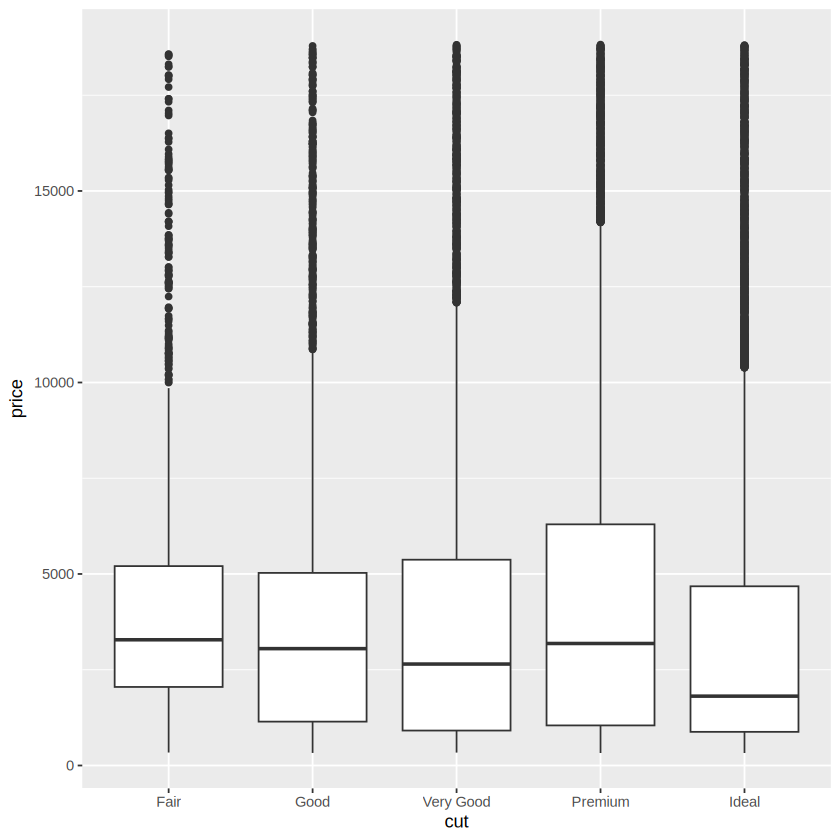

In [78]:
diamonds %>% ggplot(aes(cut, price)) + geom_boxplot()

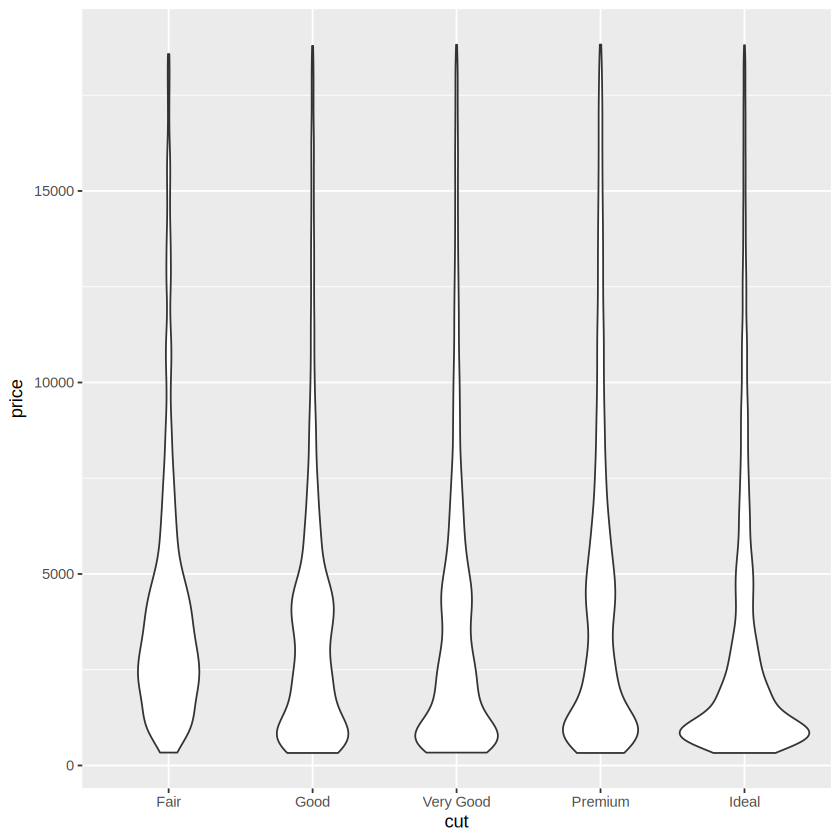

In [79]:
diamonds %>% ggplot(aes(cut, price)) + geom_violin()

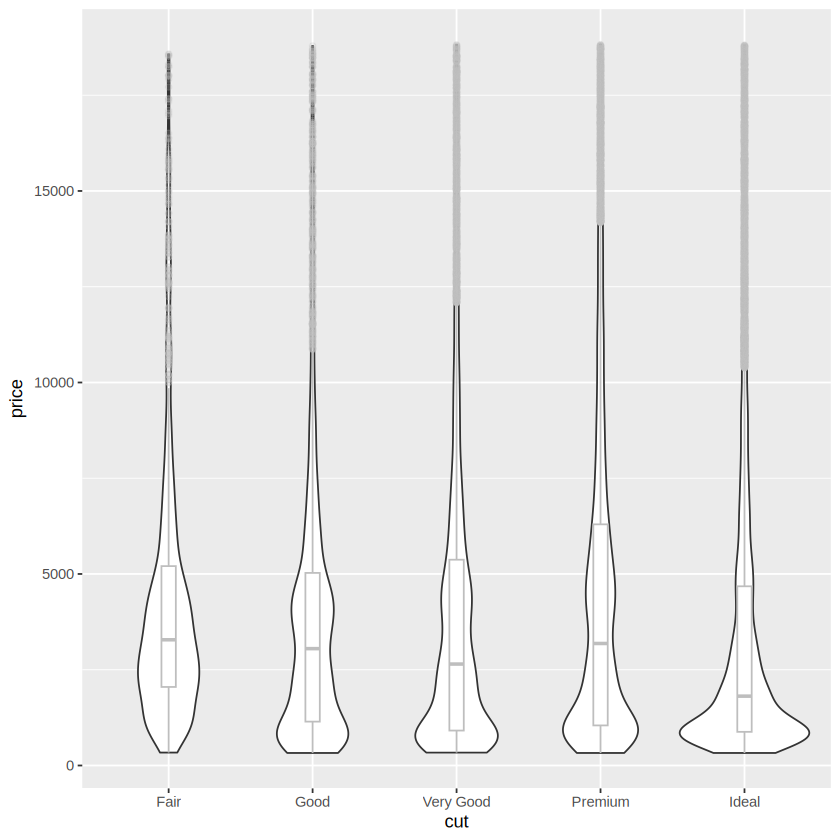

In [80]:
diamonds %>% ggplot(aes(cut, price)) + geom_violin() + geom_boxplot(width=0.1, color="grey", alpha=0.2)